
# CSL236 End-Term Project: ChessDNA: AI-Powered Chess Player Style Analyser

**Team No:** 2

**Team Members:**
- Vanshika Asthana (24csu229)
- Vasvi Yadav (24csu231)

## Project Overview

ChessDNA is an AI-powered chess player style analysis system that uses machine learning to identify different playing styles from
players' historical game statistics.

The project applies data preprocessing, exploratory data analysis,feature selection, regression, classification, dimensionality
reduction and clustering techniques to analyse chess player behaviour.

The main objective is to identify patterns in playing behaviour and classify players into understandable playing styles.

## Project Objectives

1. Analyse chess player statistics.
2. Identify important features affecting playing style.
3. Apply regression techniques to predict player statistics.
4. Apply classification techniques to predict player categories.
5. Discover playing styles using KMeans clustering.
6. Develop a system to predict the playing style of a new player.


In [21]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import silhouette_score, accuracy_score, f1_score
sns.set(style="whitegrid"); pd.set_option('display.max_columns', None); pd.set_option('display.width', 200)
from pathlib import Path
DATA_DIR = Path.cwd()
players = pd.read_csv(DATA_DIR / "chess_player_style_profiles.csv")
games = pd.read_csv(DATA_DIR / "chess_games_features.csv")
print("Player dataset:", players.shape)
print("Games dataset:", games.shape)


Player dataset: (1112, 12)
Games dataset: (4997, 22)


## Stage A : Understanding the data

### Dataset Description

The project uses a chess player dataset derived from the Lichess Elite Database (October 2025).

The dataset contains 1,112 player records and 12 columns. Each row represents an individual player whose statisticsare calculated from multiple chess games.

The dataset contains attributes such as average Elo rating,number of games played, capture rate, checks given,castling behaviour, development speed, early queen moves,pawn-move ratio and sacrifice count.

A separate game-level dataset contains 4,997 chess games and 22 attributes. It is used to extract player-level information such as preferred time control and opening family.

The player-level dataset is used for machine learningexperiments, while the game-level dataset supports feature extraction and analysis.

**Source:** Lichess Elite Database, October 2025.

Our player table (`chess_player_style_profiles.csv`) was built from game-level features and is entirely numeric. Opening choice and time control are also part of a player's style and exist in the game-level file, so we add two per-player categorical columns:
- `preferred_time_control`: the player's most common time-control type (Bullet/Blitz/Rapid/Classical, using base seconds + 40 × increment, the Lichess convention).
- `main_eco_family`: the player's most common opening family (ECO letter A–E).

Both are summaries of the player's own games, so no information leaks between players.


In [23]:
def tc_type(tc):
    try:
        base, inc = str(tc).split('+'); est = int(base) + 40 * int(inc)
    except Exception:
        return np.nan
    return 'Bullet' if est < 180 else 'Blitz' if est < 480 else 'Rapid' if est < 1500 else 'Classical'

long = pd.concat([games[['White', 'TimeControl', 'ECO']].rename(columns={'White': 'player'}),
                  games[['Black', 'TimeControl', 'ECO']].rename(columns={'Black': 'player'})])
long['tc_type'] = long['TimeControl'].map(tc_type)
long['eco_family'] = long['ECO'].astype(str).str[0].where(lambda s: s.isin(list('ABCDE')))
modal = lambda s: s.mode().iloc[0] if s.notna().any() else np.nan
cat = long.groupby('player').agg(preferred_time_control=('tc_type', modal),
                                 main_eco_family=('eco_family', modal)).reset_index()
df = players.merge(cat, on='player', how='left')

In [24]:
print("Shape:", df.shape)
print("\nData types:\n", df.dtypes)
print("\nSummary statistics:\n", df.describe().round(2).T)
missing = pd.DataFrame({'missing': df.isnull().sum(), 'percent': (df.isnull().mean() * 100).round(2)})
print("\nMissing values:\n", missing)
cat_cols = df.select_dtypes(exclude='number').columns.tolist()
num_cols = df.select_dtypes(include='number').columns.tolist()
print("\nCategorical:", cat_cols); print("Numerical:", num_cols)
print("\n", df['preferred_time_control'].value_counts()); print("\n", df['main_eco_family'].value_counts())

Shape: (1112, 14)

Data types:
 player                     object
games_played                int64
avg_elo                   float64
avg_total_moves           float64
avg_capture_rate          float64
avg_first_capture_move    float64
avg_checks_given          float64
avg_castling_move         float64
avg_dev_speed             float64
avg_queen_early_moves     float64
avg_pawn_move_ratio       float64
avg_sacrifice_count       float64
preferred_time_control     object
main_eco_family            object
dtype: object

Summary statistics:
                          count     mean     std      min      25%      50%      75%      max
games_played            1112.0     5.93    4.64     3.00     3.00     4.00     7.00    53.00
avg_elo                 1112.0  2593.65  131.90  2329.33  2515.25  2557.41  2638.42  3240.50
avg_total_moves         1112.0    86.23   21.23    27.33    72.00    84.62    95.84   204.33
avg_capture_rate        1112.0     0.22    0.03     0.12     0.20     0.22     0.23 

### Observations (Stage A)
- 1,112 players × 14 columns. Categorical: `player` (an identifier, never used as a feature), `preferred_time_control`, `main_eco_family`. The rest are numerical.
- Only `avg_castling_move` has missing values: 4 players (0.36%).
- 1,086 of 1,112 players (97.7%) are blitz players. The dataset is an elite blitz pool, so this column has very little variance. Stage G deals with that.
- **Model features:** the seven style features finalised in our EDA (capture rate, checks, castling move, development speed, early queen moves, pawn-move ratio, sacrifices) plus the encoded categorical columns. `avg_elo` and `games_played` are **not** model inputs: Elo measures strength rather than style, and `games_played` only measures how reliable a profile is. We keep Elo for describing the clusters afterwards.

## Train/test split (done before any fitting)
We split the **players** 80/20 (`random_state=42`). We first create two columns that depend only on the row itself: `castling_habit` (flags players whose `avg_castling_move` is missing) and `elo_tier` (fixed bins, see Stage D). These involve no learning from other rows, so they cannot leak. Every fitted step from here on (imputers, encoder, scaler, filters, PCA, KMeans) is fitted on `train` only and then applied to `test`.

In [4]:
df['castling_habit'] = np.where(df['avg_castling_move'].isna(), 'Non-castler', 'Castler')
df['elo_tier'] = pd.cut(df['avg_elo'], [0, 2450, 2550, 2650, 2750, 5000], right=False,
                        labels=['<2450', '2450-2549', '2550-2649', '2650-2749', '2750+'])
NUM = ['avg_capture_rate', 'avg_checks_given', 'avg_castling_move', 'avg_dev_speed',
       'avg_queen_early_moves', 'avg_pawn_move_ratio', 'avg_sacrifice_count']
train, test = train_test_split(df, test_size=0.2, random_state=42)
train, test = train.copy(), test.copy()
print("Train:", train.shape, "| Test:", test.shape)

Train: (889, 16) | Test: (223, 16)


## Stage B: Handling missing values
**Only `avg_castling_move` is affected (4 players).** The missing value is not random: it means the player *never castled* in any of their games. Decisions:
- **Keep the rows.** Dropping them would remove the unusual "never castles" style we want to detect.
- **Impute with the median**, fitted on training data. The column is right-skewed, so the median is more robust than the mean.
- **Keep the information that the value was imputed** via the binary flag `castling_habit`.
- Categorical columns have no missing values, but a most-frequent (mode) imputer is fitted anyway so new data would be handled consistently.

*Alternatives rejected:* the mean is pulled by the long tail. A constant such as 0 is impossible (castling cannot happen on move 0) and would fake an extremely early castler. Dropping rows loses data.

In [5]:
CAT_IMP = ['preferred_time_control', 'main_eco_family']
print("Missing in train:\n", train[NUM + CAT_IMP].isnull().sum()[lambda s: s > 0])
num_imp = SimpleImputer(strategy='median').fit(train[NUM])
cat_imp = SimpleImputer(strategy='most_frequent').fit(train[CAT_IMP])
for d in (train, test):
    d[NUM] = num_imp.transform(d[NUM]); d[CAT_IMP] = cat_imp.transform(d[CAT_IMP])
print("Median used for avg_castling_move:", round(num_imp.statistics_[NUM.index('avg_castling_move')], 2))
print("Missing after imputation (train/test):", train[NUM + CAT_IMP].isnull().sum().sum(), test[NUM + CAT_IMP].isnull().sum().sum())
pre_log = train[NUM].copy()   # kept for the outlier comparison in Stage F

Missing in train:
 avg_castling_move    4
dtype: int64
Median used for avg_castling_move: 9.43
Missing after imputation (train/test): 0 0


## Stage C : Encoding categorical data
| Column | Type | Scheme | Why |
|---|---|---|---|
| `castling_habit` | binary | 0/1 map: Non-castler = 0, Castler = 1 | two categories |
| `preferred_time_control` | ordinal | **explicit order** Bullet (0) < Blitz (1) < Rapid (2) < Classical (3) | more thinking time per move |
| `elo_tier` | ordinal | explicit order `<2450` (0) < `2450-2549` (1) < `2550-2649` (2) < `2650-2749` (3) < `2750+` (4) | ordered rating bands (used for profiling only) |
| `main_eco_family` | nominal | one-hot (fitted on train, unknown categories ignored) | ECO letters A–E have no order |

Label-encoding ECO letters would imply a false order (A < B < C), so one-hot is the correct choice. `player` is an identifier: encoding 1,112 unique names would create a column per player and generalise to nobody, so it is excluded.

In [6]:
tc_order = {'Bullet': 0, 'Blitz': 1, 'Rapid': 2, 'Classical': 3}
tier_order = {'<2450': 0, '2450-2549': 1, '2550-2649': 2, '2650-2749': 3, '2750+': 4}
ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False).fit(train[['main_eco_family']])
eco_cols = [f'eco_{c}' for c in ohe.categories_[0]]
for d in (train, test):
    d['castling_habit_bin'] = d['castling_habit'].map({'Non-castler': 0, 'Castler': 1})
    d['time_control_ord'] = d['preferred_time_control'].map(tc_order)
    d['elo_tier_ord'] = d['elo_tier'].astype(str).map(tier_order)
    d[eco_cols] = ohe.transform(d[['main_eco_family']])
train[['castling_habit', 'castling_habit_bin', 'preferred_time_control', 'time_control_ord',
       'main_eco_family'] + eco_cols].head()

,castling_habit,castling_habit_bin,preferred_time_control,time_control_ord,main_eco_family,eco_A,eco_B,eco_C,eco_D,eco_E
866,Castler,1,Blitz,1,D,0.0,0.0,0.0,1.0,0.0
994,Castler,1,Blitz,1,C,0.0,0.0,1.0,0.0,0.0
1024,Castler,1,Blitz,1,A,1.0,0.0,0.0,0.0,0.0
781,Castler,1,Blitz,1,B,0.0,1.0,0.0,0.0,0.0
898,Castler,1,Blitz,1,A,1.0,0.0,0.0,0.0,0.0


## Stage D: Binning / discretization
**Applied to `avg_elo` → `elo_tier`** using domain-defined 100-point bands: <2450, 2450–2549, 2550–2649, 2650–2749, 2750+. Rating bands are how chess players naturally talk about strength. The boundaries are fixed in advance rather than learned from the data, so there is no leakage and the bins stay readable. We use the tiers afterwards to check whether our style clusters are just strength groups in disguise.

**Deliberately not applied to the style features.** They are continuous and PCA/KMeans work on distances between them. Binning would throw away the fine differences we are trying to detect. Equal-frequency bins were considered but their edges change with the data, which makes them harder to interpret.

elo_tier
<2450         54
2450-2549    357
2550-2649    275
2650-2749    106
2750+         97
Name: count, dtype: int64


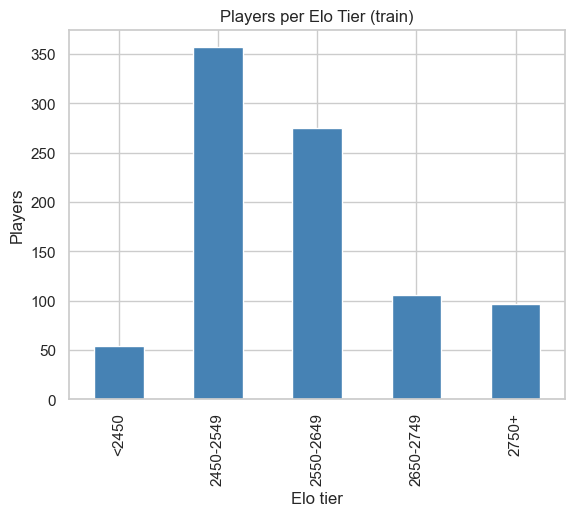

In [7]:
tier_counts = train['elo_tier'].value_counts().sort_index()
print(tier_counts)
tier_counts.plot(kind='bar', color='steelblue'); plt.title('Players per Elo Tier (train)')
plt.xlabel('Elo tier'); plt.ylabel('Players'); plt.show()

## Stage E: Scaling and transformation
**Transformation:** we measure skewness on the training data and apply `log1p` to any style feature with |skew| > 1. We use `log(1 + x)` rather than `log(x)` because some values (e.g. early queen moves) can be 0. This selects `avg_checks_given` (skew 1.24) and `avg_queen_early_moves` (skew 1.10).

**Scaling:** `StandardScaler` (mean 0, std 1), fitted on train. PCA and KMeans are variance/distance-based, and our features live on very different scales (checks go up to ~23, capture rate is only 0.12–0.30), so without scaling the large-valued features would dominate. Binary/one-hot columns are already bounded in 0/1 and are left as they are.

*Alternative considered:* MinMax scaling. It is more sensitive to extreme values, and we keep extreme players (see Stage F).

Skewness (train):
 avg_capture_rate        -0.02
avg_checks_given         1.24
avg_castling_move        0.86
avg_dev_speed            0.66
avg_queen_early_moves    1.10
avg_pawn_move_ratio      0.65
avg_sacrifice_count      0.35
dtype: float64
Log-transformed: ['avg_checks_given', 'avg_queen_early_moves']


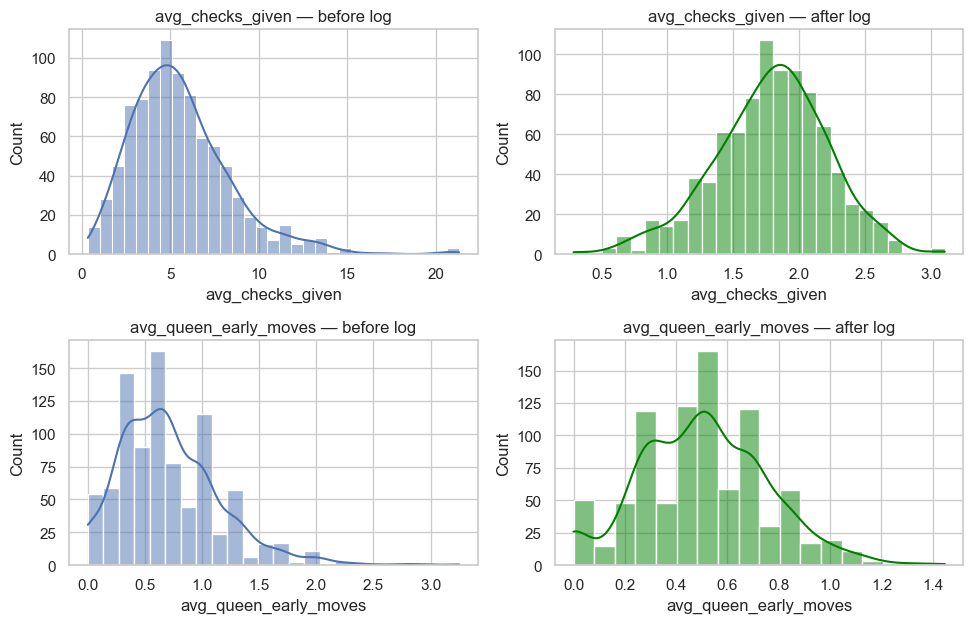

      avg_capture_rate  avg_checks_given  avg_castling_move  avg_dev_speed  avg_queen_early_moves  avg_pawn_move_ratio  avg_sacrifice_count
mean              -0.0              -0.0               -0.0            0.0                   -0.0                 -0.0                  0.0
std                1.0               1.0                1.0            1.0                    1.0                  1.0                  1.0


In [8]:
skew = train[NUM].skew().round(2); print("Skewness (train):\n", skew)
log_cols = skew[skew.abs() > 1].index.tolist(); print("Log-transformed:", log_cols)
for d in (train, test):
    d[log_cols] = np.log1p(d[log_cols])
fig, axes = plt.subplots(len(log_cols), 2, figsize=(10, 3.2 * len(log_cols)))
for i, c in enumerate(log_cols):
    sns.histplot(pre_log[c], kde=True, ax=axes[i, 0]); axes[i, 0].set_title(f'{c} — before log')
    sns.histplot(train[c], kde=True, ax=axes[i, 1], color='green'); axes[i, 1].set_title(f'{c} — after log')
plt.tight_layout(); plt.show()
scaler = StandardScaler().fit(train[NUM])
for d in (train, test):
    d[NUM] = scaler.transform(d[NUM])
print(train[NUM].describe().loc[['mean', 'std']].round(2))

## Stage F: Outlier treatment
We apply the IQR rule (outside Q1 − 1.5·IQR to Q3 + 1.5·IQR) on the training data, before and after the log transform, and investigate rather than delete.

                       outliers_before_log  outliers_after_log
avg_capture_rate                        22                  22
avg_checks_given                        27                  17
avg_castling_move                       19                  19
avg_dev_speed                           15                  15
avg_queen_early_moves                    7                   3
avg_pawn_move_ratio                     29                  29
avg_sacrifice_count                      9                   9

Players flagged on >=1 feature: 110 of 889
Mean games_played — outlier players: 5.85 | others: 5.91
Value ranges:
                          min     max
avg_capture_rate       0.118   0.296
avg_checks_given       0.333  21.333
avg_castling_move      4.000  23.000
avg_dev_speed          8.000  26.000
avg_queen_early_moves  0.000   3.250
avg_pawn_move_ratio    0.142   0.548
avg_sacrifice_count    0.333   8.333


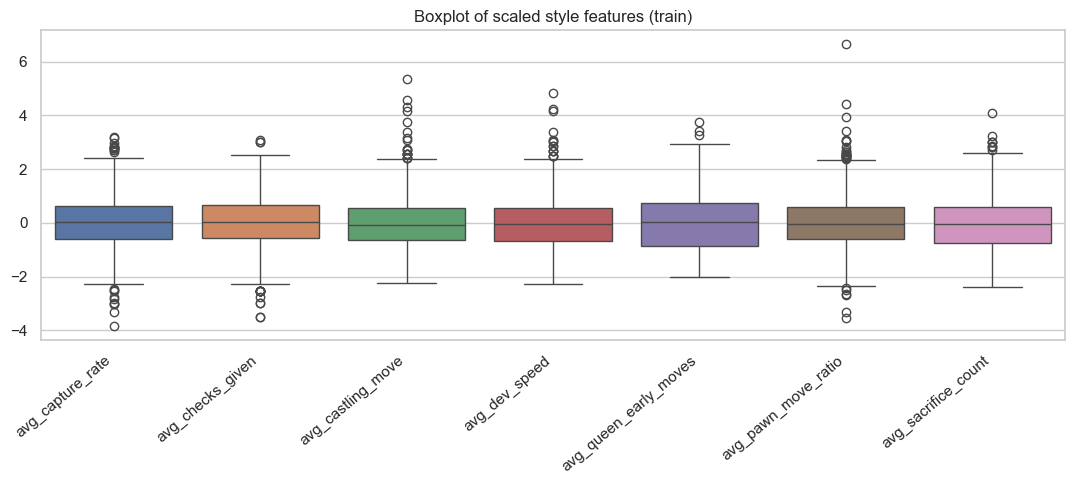

In [9]:
def iqr_counts(X):
    q1, q3 = X.quantile(.25), X.quantile(.75); i = q3 - q1
    return ((X < q1 - 1.5 * i) | (X > q3 + 1.5 * i)).sum()
out_tbl = pd.DataFrame({'outliers_before_log': iqr_counts(pre_log), 'outliers_after_log': iqr_counts(train[NUM])})
print(out_tbl)
q1, q3 = pre_log.quantile(.25), pre_log.quantile(.75); i = q3 - q1
is_out = ((pre_log < q1 - 1.5 * i) | (pre_log > q3 + 1.5 * i)).any(axis=1)
print(f"\nPlayers flagged on >=1 feature: {is_out.sum()} of {len(train)}")
print("Mean games_played — outlier players:", round(train.loc[is_out, 'games_played'].mean(), 2),
      "| others:", round(train.loc[~is_out, 'games_played'].mean(), 2))
print("Value ranges:\n", pre_log.agg(['min', 'max']).round(3).T)
plt.figure(figsize=(11, 5)); sns.boxplot(data=train[NUM]); plt.xticks(rotation=40, ha='right')
plt.title('Boxplot of scaled style features (train)'); plt.tight_layout(); plt.show()

### Decision (Stage F)
- **Genuine, not errors.** All values are in valid ranges: capture rate 0.12–0.30, pawn-move ratio 0.14–0.55 (both between 0 and 1), counts non-negative. Nothing is impossible.
- **Not small-sample noise.** Flagged players have the same average `games_played` as the rest (5.85 vs 5.91), so their extreme values are not just a few-game fluke.
- **110 of 889 training players (12%)** are flagged on at least one feature. Deleting them would remove the extreme styles (heavy attackers, very quiet players) this project exists to find.
- **Treatment: retain.** The log transform already reduced flags for `avg_checks_given` (27 → 17) and `avg_queen_early_moves` (7 → 3). KMeans is sensitive to outliers, so in Stage H we check that the clusters are not dominated by a few extreme players.

## Stage G : Dimensionality reduction
**Starting features: 14** (7 numeric style features + `castling_habit_bin` + `time_control_ord` + 5 ECO dummies).

**Feature selection**
1. *Near-constant filter:* drop any feature where one value covers more than 95% of training rows, since it cannot separate players. This removes `castling_habit_bin` (99.6% Castler), `time_control_ord` (97.8% Blitz) and `eco_E` (97.3% zeros). This is itself a finding: the elite blitz pool has almost no variation in time control or castling habit. A variance threshold was not used because it depends on a feature's units, and after scaling every numeric column has variance 1.
2. *Correlation filter (|r| > 0.85):* the highest pairwise correlation is 0.57, so no feature is redundant. This is consistent with our EDA.

**Feature extraction:** PCA keeping 90% of the variance, which gives uncorrelated components, reduces noise and lets us plot the players in 2D.

Features at start: 14
Near-constant (>95% one value) dropped: {'castling_habit_bin': np.float64(0.996), 'time_control_ord': np.float64(0.978), 'eco_E': np.float64(0.973)}
Highest pairwise |r|: 0.57 | dropped by correlation filter: []
After selection: 11


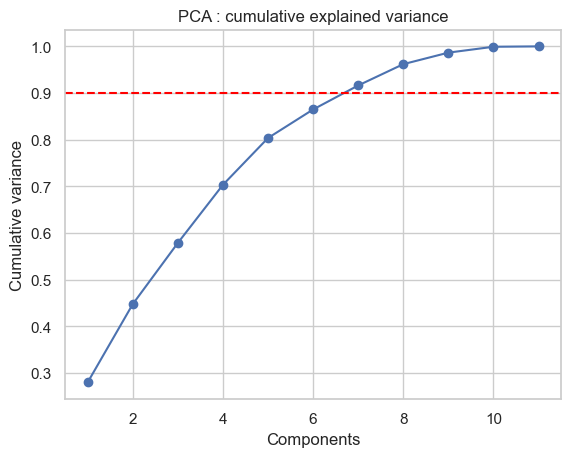

Features: 14 -> 11 (selection) -> 7 PCA components


In [25]:
FEATS = NUM + ['castling_habit_bin', 'time_control_ord'] + eco_cols
print("Features at start:", len(FEATS))
dominant = {c: train[c].value_counts(normalize=True).iloc[0] for c in FEATS}
near_const = [c for c, v in dominant.items() if v > 0.95]
print("Near-constant (>95% one value) dropped:", {c: round(dominant[c], 3) for c in near_const})
F1 = [c for c in FEATS if c not in near_const]
corr = train[F1].corr().abs(); upper = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool))
high_corr = [c for c in upper.columns if (upper[c] > 0.85).any()]
print("Highest pairwise |r|:", round(upper.max().max(), 2), "| dropped by correlation filter:", high_corr)
F2 = [c for c in F1 if c not in high_corr]; print("After selection:", len(F2))

pca_full = PCA(random_state=42).fit(train[F2])
plt.plot(range(1, len(F2) + 1), pca_full.explained_variance_ratio_.cumsum(), marker='o'); plt.axhline(0.90, color='red', ls='--')
plt.xlabel('Components'); plt.ylabel('Cumulative variance'); plt.title('PCA : cumulative explained variance'); plt.show()
pca = PCA(n_components=0.90, random_state=42).fit(train[F2])
Ztr, Zte = pca.transform(train[F2]), pca.transform(test[F2])
print(f"Features: {len(FEATS)} -> {len(F2)} (selection) -> {pca.n_components_} PCA components")

## Stage H: Model training
**Model:** KMeans clustering on the 7 PCA components. There is no label column, so this is unsupervised learning. **Metric:** silhouette score (−1 to 1; higher means tighter, better-separated clusters), computed on train, and on test using the clusters the trained model assigns to unseen players.

**Choosing k:** we compute the silhouette for k = 2…7 on train. k = 2 scores marginally highest (0.167), but we use **k = 3** (0.133) because we want to separate more than two styles, and three groups remain interpretable. All silhouettes are low (0.12–0.17), meaning playing style is a continuum with overlapping groups, not sharply separated types. We report this honestly.

{2: np.float64(0.167), 3: np.float64(0.133), 4: np.float64(0.116), 5: np.float64(0.117), 6: np.float64(0.125), 7: np.float64(0.117)}


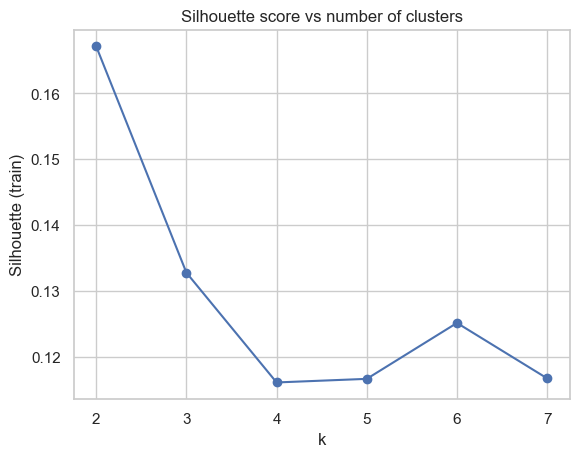

In [11]:
ks = range(2, 8)
sil = [silhouette_score(Ztr, KMeans(k, n_init=10, random_state=42).fit_predict(Ztr)) for k in ks]
print(dict(zip(ks, np.round(sil, 3))))
plt.plot(list(ks), sil, marker='o'); plt.xlabel('k'); plt.ylabel('Silhouette (train)')
plt.title('Silhouette score vs number of clusters'); plt.show()

Silhouette — train: 0.133 | test: 0.1
Cluster sizes — train: [298 316 275] | test: [73 80 70]
                        avg_capture_rate  avg_checks_given  avg_castling_move  avg_dev_speed  avg_queen_early_moves  avg_pawn_move_ratio  avg_sacrifice_count
Tactical attacker                   0.20              7.86               8.82          13.79                   0.63                 0.25                 4.11
Early-queen risk-taker              0.23              5.24              11.10          13.80                   1.00                 0.29                 3.43
Quiet / positional                  0.22              3.38               8.73          13.61                   0.46                 0.31                 2.19
elo_tier                <2450  2450-2549  2550-2649  2650-2749  2750+
style                                                                
Early-queen risk-taker   0.05       0.41       0.33       0.14   0.06
Quiet / positional       0.07       0.47       0.30       0.09  

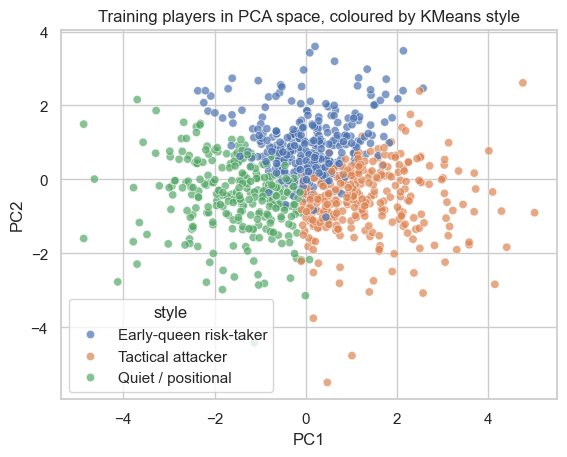

In [12]:
K = 3
km = KMeans(K, n_init=10, random_state=42).fit(Ztr)
tr_lab, te_lab = km.labels_, km.predict(Zte)
print("Silhouette — train:", round(silhouette_score(Ztr, tr_lab), 3), "| test:", round(silhouette_score(Zte, te_lab), 3))
print("Cluster sizes — train:", np.bincount(tr_lab), "| test:", np.bincount(te_lab))

raw = df.loc[train.index, NUM]                     # original (unscaled) values for interpretation
profile = raw.groupby(tr_lab).mean()
names = {c: 'Early-queen risk-taker' for c in range(K)}
names[profile['avg_checks_given'].idxmax()] = 'Tactical attacker'
names[profile['avg_checks_given'].idxmin()] = 'Quiet / positional'
profile.index = [names[c] for c in profile.index]; print(profile.round(2))

style = pd.Series([names[c] for c in tr_lab], index=train.index, name='style')
print(pd.crosstab(style, train['elo_tier'], normalize='index').round(2))
plot_df = pd.DataFrame(Ztr[:, :2], columns=['PC1', 'PC2']); plot_df['style'] = style.values
sns.scatterplot(data=plot_df, x='PC1', y='PC2', hue='style', alpha=0.7)
plt.title('Training players in PCA space, coloured by KMeans style'); plt.show()

### Interpreting the clusters (from the profile table above)
- **Tactical attacker:** most checks (7.9) and sacrifices (4.1), and castles early (move ~8.8).
- **Early-queen risk-taker:** most early queen moves (1.0), castles late (move ~11.1), highest capture rate (0.23).
- **Quiet / positional:** fewest checks (3.4) and sacrifices (2.2), fewest early queen moves (0.46), highest pawn-move ratio (0.31).

The three groups are balanced in size (298 / 316 / 275 on train), so a few extreme players are not dominating the clustering. Elo-tier mixes are broadly similar across groups, which supports "style is not just strength". The one exception is that the tactical group has a larger share of 2750+ players (19% vs 6–8%). That is worth noting, but there are only 97 players in the top tier, so we do not over-read it.

In [13]:
clf = LogisticRegression(max_iter=2000).fit(Ztr, tr_lab)
pred = clf.predict(Zte)
print("Accuracy:", round(accuracy_score(te_lab, pred), 3), "| Macro F1:", round(f1_score(te_lab, pred, average='macro'), 3),
      "| Majority-class baseline:", round(np.bincount(te_lab).max() / len(te_lab), 3))

Accuracy: 0.978 | Macro F1: 0.978 | Majority-class baseline: 0.359


### Predicting a new player's style
A new player must go through the same fitted pipeline as the training players: impute, encode, log, scale, select features, PCA, then assign the nearest cluster. We reuse the already-fitted objects and never refit on new data. The test cases below check that typical players land in the expected style and that missing values, outliers and average players are handled without errors.

In [14]:
summary = pd.DataFrame([
    ['Missing values', 'avg_castling_move', 'Median imputation (fit on train) + castling_habit flag', 'Never-castled players kept; median robust to skew'],
    ['Binary encoding', 'castling_habit', '0/1 mapping', 'Two categories'],
    ['Ordinal encoding', 'preferred_time_control, elo_tier', 'Explicit order mapping', 'Categories have natural order'],
    ['Nominal encoding', 'main_eco_family', 'One-hot (fit on train)', 'ECO letters have no order'],
    ['Binning', 'avg_elo -> elo_tier', 'Domain-defined 100-point bands', 'Used to profile clusters, not as model input'],
    ['Transformation', 'avg_checks_given, avg_queen_early_moves', 'log1p (|skew| > 1 on train)', 'Reduce right skew and outlier leverage'],
    ['Scaling', '7 numeric style features', 'StandardScaler (fit on train)', 'KMeans/PCA are scale-sensitive'],
    ['Outliers', '7 numeric style features', 'IQR detection; retained', 'Valid ranges, genuine extreme styles'],
    ['Feature selection', '14 features', 'Near-constant filter (>95%), correlation filter (|r|>0.85)', 'Drop features that cannot separate players'],
    ['Feature extraction', '11 features', 'PCA, 90% variance', 'Compress to fewer uncorrelated dimensions'],
], columns=['Stage', 'Columns', 'Technique', 'Reason'])
summary

,Stage,Columns,Technique,Reason
0,Missing values,avg_castling_move,Median imputation (fit on train) + castling_ha...,Never-castled players kept; median robust to skew
1,Binary encoding,castling_habit,0/1 mapping,Two categories
2,Ordinal encoding,"preferred_time_control, elo_tier",Explicit order mapping,Categories have natural order
3,Nominal encoding,main_eco_family,One-hot (fit on train),ECO letters have no order
4,Binning,avg_elo -> elo_tier,Domain-defined 100-point bands,"Used to profile clusters, not as model input"
5,Transformation,"avg_checks_given, avg_queen_early_moves",log1p (|skew| > 1 on train),Reduce right skew and outlier leverage
6,Scaling,7 numeric style features,StandardScaler (fit on train),KMeans/PCA are scale-sensitive
7,Outliers,7 numeric style features,IQR detection; retained,"Valid ranges, genuine extreme styles"
8,Feature selection,14 features,"Near-constant filter (>95%), correlation filte...",Drop features that cannot separate players
9,Feature extraction,11 features,"PCA, 90% variance",Compress to fewer uncorrelated dimensions


In [16]:
def predict_style(new):
    """new: DataFrame, one row per player, with RAW (unscaled) values for the 7 style
    features in NUM plus preferred_time_control and main_eco_family. NaN is allowed."""
    x = new.copy()
    x['castling_habit_bin'] = np.where(x['avg_castling_move'].isna(), 0, 1)  # flag BEFORE imputing
    x[NUM] = num_imp.transform(x[NUM])                    # same median imputer
    x[CAT_IMP] = cat_imp.transform(x[CAT_IMP])            # same mode imputer
    x['time_control_ord'] = x['preferred_time_control'].map(tc_order)
    x[eco_cols] = ohe.transform(x[['main_eco_family']])   # same one-hot encoder
    x[log_cols] = np.log1p(x[log_cols])                   # same log columns
    x[NUM] = scaler.transform(x[NUM])                     # same scaler
    Z = pca.transform(x[F2])                              # same selected features + PCA
    out = pd.DataFrame({'style (KMeans)': [names[c] for c in km.predict(Z)]}, index=new.index)
    proba = pd.DataFrame(clf.predict_proba(Z), columns=[names[c] for c in clf.classes_], index=new.index)
    return pd.concat([out, proba.round(2)], axis=1)

# Example: a new player's averaged stats
new_player = pd.DataFrame([{
    'avg_capture_rate': 0.20, 'avg_checks_given': 8.0, 'avg_castling_move': 8.5,
    'avg_dev_speed': 13.5, 'avg_queen_early_moves': 0.6, 'avg_pawn_move_ratio': 0.25,
    'avg_sacrifice_count': 4.2, 'preferred_time_control': 'Blitz', 'main_eco_family': 'B'}],
    index=['new_player'])
predict_style(new_player)

,style (KMeans),Tactical attacker,Early-queen risk-taker,Quiet / positional
new_player,Tactical attacker,1.0,0.0,0.0


In [17]:
base = dict(avg_capture_rate=0.216, avg_checks_given=5.5, avg_castling_move=9.6, avg_dev_speed=13.7,
            avg_queen_early_moves=0.7, avg_pawn_move_ratio=0.28, avg_sacrifice_count=3.3,
            preferred_time_control='Blitz', main_eco_family='B')   # roughly the dataset average

cases = {
 '1 Heavy attacker':          dict(avg_capture_rate=0.20, avg_checks_given=8.5, avg_castling_move=8.5,
                                   avg_queen_early_moves=0.6, avg_pawn_move_ratio=0.25, avg_sacrifice_count=4.5),
 '2 Early-queen/late-castle': dict(avg_capture_rate=0.23, avg_checks_given=5.2, avg_castling_move=11.5,
                                   avg_queen_early_moves=1.1, avg_pawn_move_ratio=0.29, avg_sacrifice_count=3.4,
                                   main_eco_family='A'),
 '3 Quiet positional':        dict(avg_capture_rate=0.22, avg_checks_given=3.2, avg_castling_move=8.7,
                                   avg_queen_early_moves=0.4, avg_pawn_move_ratio=0.32, avg_sacrifice_count=2.0,
                                   main_eco_family='D'),
 '4 Never castles (NaN)':     dict(avg_castling_move=np.nan, avg_checks_given=6.0, avg_sacrifice_count=3.5),
 '5 Extreme outlier':         dict(avg_checks_given=20.0, avg_sacrifice_count=8.0, avg_queen_early_moves=3.0),
 '6 Rapid, missing opening':  dict(preferred_time_control='Rapid', main_eco_family=np.nan),
 '7 Dead-average player':     dict(),
}
test_df = pd.DataFrame([{**base, **v} for v in cases.values()], index=list(cases.keys()))
predict_style(test_df)

,style (KMeans),Tactical attacker,Early-queen risk-taker,Quiet / positional
1 Heavy attacker,Tactical attacker,1.00,0.00,0.00
2 Early-queen/late-castle,Early-queen risk-taker,0.00,1.00,0.00
3 Quiet positional,Quiet / positional,0.00,0.00,1.00
4 Never castles (NaN),Early-queen risk-taker,0.29,0.71,0.00
5 Extreme outlier,Tactical attacker,0.83,0.17,0.00
"6 Rapid, missing opening",Early-queen risk-taker,0.16,0.82,0.02
7 Dead-average player,Early-queen risk-taker,0.12,0.87,0.01


In [18]:
cols = ['avg_capture_rate','avg_checks_given','avg_castling_move','avg_dev_speed','avg_queen_early_moves',
        'avg_pawn_move_ratio','avg_sacrifice_count','preferred_time_control','main_eco_family']

rows = {
 'P01 Attacker, e4 player':      [0.19, 9.0, 8.0, 13.5, 0.5, 0.24, 4.8, 'Blitz', 'C'],
 'P02 Attacker, sac-heavy':      [0.21, 8.0, 9.0, 13.0, 0.7, 0.26, 5.5, 'Blitz', 'B'],
 'P03 Risk-taker, late castle':  [0.24, 5.0, 12.0, 14.0, 1.2, 0.29, 3.5, 'Blitz', 'A'],
 'P04 Risk-taker, queen out':    [0.23, 5.5, 11.0, 13.8, 1.5, 0.30, 3.2, 'Blitz', 'A'],
 'P05 Quiet, d4 player':         [0.22, 3.0, 8.5, 13.5, 0.3, 0.33, 2.0, 'Blitz', 'D'],
 'P06 Quiet, low sacrifices':    [0.21, 3.5, 9.0, 14.0, 0.4, 0.31, 1.8, 'Rapid', 'D'],
 'P07 Borderline att/quiet':     [0.21, 5.5, 9.0, 13.5, 0.5, 0.28, 3.0, 'Blitz', 'B'],
 'P08 Never castles':            [0.22, 6.0, np.nan, 13.7, 0.7, 0.28, 3.3, 'Blitz', 'B'],
 'P09 Extreme checks':           [0.20, 20.0, 8.5, 13.5, 0.6, 0.25, 6.0, 'Blitz', 'C'],
 'P10 Missing opening (NaN)':    [0.22, 4.0, 9.5, 13.5, 0.5, 0.30, 2.5, 'Blitz', np.nan],
 'P11 Dataset average':          [0.216, 5.5, 9.6, 13.7, 0.7, 0.28, 3.3, 'Blitz', 'B'],
 'P12 Slow developer, passive':  [0.22, 3.8, 10.5, 18.0, 0.4, 0.34, 2.2, 'Blitz', 'E'],
}
inp = pd.DataFrame.from_dict(rows, orient='index', columns=cols)
predict_style(inp)

,style (KMeans),Tactical attacker,Early-queen risk-taker,Quiet / positional
"P01 Attacker, e4 player",Tactical attacker,1.00,0.00,0.00
"P02 Attacker, sac-heavy",Tactical attacker,1.00,0.00,0.00
"P03 Risk-taker, late castle",Early-queen risk-taker,0.00,1.00,0.00
"P04 Risk-taker, queen out",Early-queen risk-taker,0.00,1.00,0.00
"P05 Quiet, d4 player",Quiet / positional,0.00,0.00,1.00
"P06 Quiet, low sacrifices",Quiet / positional,0.00,0.00,1.00
P07 Borderline att/quiet,Tactical attacker,0.56,0.21,0.23
P08 Never castles,Early-queen risk-taker,0.15,0.85,0.01
P09 Extreme checks,Tactical attacker,1.00,0.00,0.00
P10 Missing opening (NaN),Quiet / positional,0.00,0.02,0.98


In [19]:
import joblib, sklearn, sys
bundle = dict(num_imp=num_imp, cat_imp=cat_imp, ohe=ohe, scaler=scaler, pca=pca, km=km, clf=clf,
              names=names, NUM=NUM, CAT_IMP=CAT_IMP, eco_cols=eco_cols, F2=F2, log_cols=log_cols,
              tc_order=tc_order, profile=profile)
joblib.dump(bundle, 'style_model.joblib')
print("Python", sys.version.split()[0])
print(f"scikit-learn=={sklearn.__version__}\nnumpy=={np.__version__}\npandas=={pd.__version__}\njoblib=={joblib.__version__}")

Python 3.14.0
scikit-learn==1.8.0
numpy==2.3.5
pandas==2.3.3
joblib==1.5.3



# Stage I: Supervised Learning – Problem Definitions

In addition to discovering chess-playing styles through unsupervised learning, supervised machine learning is used to predict player characteristics.

Four problem statements are considered:

### Regression Problems

**P1: Predict Average Elo Rating**

Predict the average Elo rating of a chess player using their playing-style features.

Target variable: avg_elo

**P6: Predict Average Game Length**

Predict the average number of moves played in a player's games using their playing-style features and average Elo.

Target variable: avg_total_moves

### Classification Problems

**P2: High-Potential Player Identification**

Identify whether a player has an Elo rating above the median Elo of players belonging to a similar games-played group.

Target variable: Binary category (0 or 1).

**P3: Risky Playing Style Identification**

Identify players having both above-median sacrifice counts and above-median checks given.

Target variable: Binary category (0 or 1).

These experiments extend the main clustering analysis by studying numerical prediction and categorical classification of chess player characteristics.


In [34]:

# Define the playing-style features
STYLE = [
    'avg_capture_rate',
    'avg_first_capture_move',
    'avg_checks_given',
    'avg_castling_move',
    'avg_dev_speed',
    'avg_queen_early_moves',
    'avg_pawn_move_ratio',
    'avg_sacrifice_count'
]

# Dictionary to store all four problems
problems = {}

# P1: Predict average Elo rating
problems['P1: Predict avg_elo'] = {
    'kind': 'regression',
    'features': STYLE,
    'target': df['avg_elo']
}

# P6: Predict average game length
problems['P6: Predict game length'] = {
    'kind': 'regression',
    'features': STYLE + ['avg_elo'],
    'target': df['avg_total_moves']
}

# P2: High-potential player identification
bracket = pd.qcut(
    df['games_played'].rank(method='first'),
    3,
    labels=False
)

bracket_median = df.groupby(bracket)['avg_elo'].transform('median')

problems['P2: High-potential'] = {
    'kind': 'classification',
    'features': STYLE,
    'target': (df['avg_elo'] > bracket_median).astype(int)
}

# P3: Risky playing-style identification
risky = (
    (df['avg_sacrifice_count'] > df['avg_sacrifice_count'].median()) &
    (df['avg_checks_given'] > df['avg_checks_given'].median())
).astype(int)

problems['P3: Risky style'] = {
    'kind': 'classification',
    'features': [
        c for c in STYLE
        if c not in ['avg_sacrifice_count', 'avg_checks_given']
    ],
    'target': risky
}

# Display the problem definitions
for name, problem in problems.items():
    print("\n", name)
    print("Type:", problem['kind'])
    print("Features:", problem['features'])
    print("Target distribution:")
    print(problem['target'].value_counts() if problem['kind'] == 'classification'
          else problem['target'].describe())



 P1: Predict avg_elo
Type: regression
Features: ['avg_capture_rate', 'avg_first_capture_move', 'avg_checks_given', 'avg_castling_move', 'avg_dev_speed', 'avg_queen_early_moves', 'avg_pawn_move_ratio', 'avg_sacrifice_count']
Target distribution:
count    1112.000000
mean     2593.651442
std       131.900466
min      2329.333000
25%      2515.250000
50%      2557.411000
75%      2638.416500
max      3240.500000
Name: avg_elo, dtype: float64

 P6: Predict game length
Type: regression
Features: ['avg_capture_rate', 'avg_first_capture_move', 'avg_checks_given', 'avg_castling_move', 'avg_dev_speed', 'avg_queen_early_moves', 'avg_pawn_move_ratio', 'avg_sacrifice_count', 'avg_elo']
Target distribution:
count    1112.000000
mean       86.229361
std        21.231703
min        27.333000
25%        72.000000
50%        84.619000
75%        95.839000
max       204.333000
Name: avg_total_moves, dtype: float64

 P2: High-potential
Type: classification
Features: ['avg_capture_rate', 'avg_first_captu


# Stage J: Regression Analysis

Regression is a supervised machine learning technique
used to predict continuous numerical values.

Two regression problems are considered:

1. Predicting average Elo rating (P1).
2. Predicting average game length (P6).

The following algorithms are applied:

- Multiple Linear Regression
- Polynomial Regression
- KNN Regression
- Decision Tree Regression

The models are evaluated using MAE, MSE, RMSE
and R-squared.


In [35]:

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

import numpy as np
import pandas as pd

regression_models = {
    'Multiple Linear Regression': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('model', LinearRegression())
    ]),

    'Polynomial Regression': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler1', StandardScaler()),
        ('poly', PolynomialFeatures(degree=2, include_bias=False)),
        ('scaler2', StandardScaler()),
        ('model', LinearRegression())
    ]),

    'KNN Regression': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('model', KNeighborsRegressor(n_neighbors=5))
    ]),

    'Decision Tree Regression': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('model', DecisionTreeRegressor(max_depth=5, random_state=42))
    ])
}


In [36]:

regression_results = []
trained_regression_models = {}

for pname, problem in problems.items():

    if problem['kind'] != 'regression':
        continue

    X = df[problem['features']]
    y = problem['target']

    X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
        X, y,
        test_size=0.2,
        random_state=42
    )

    for model_name, model in regression_models.items():

        model.fit(X_train_r, y_train_r)
        predictions = model.predict(X_test_r)

        mse = mean_squared_error(y_test_r, predictions)

        regression_results.append({
            'Problem': pname,
            'Algorithm': model_name,
            'MAE': mean_absolute_error(y_test_r, predictions),
            'MSE': mse,
            'RMSE': np.sqrt(mse),
            'R2 Score': r2_score(y_test_r, predictions)
        })

        trained_regression_models[(pname, model_name)] = model

regression_results = pd.DataFrame(regression_results)

display(regression_results.round(4))


,Problem,Algorithm,MAE,MSE,RMSE,R2 Score
0,P1: Predict avg_elo,Multiple Linear Regression,88.0264,13482.7870,116.1154,0.0355
1,P1: Predict avg_elo,Polynomial Regression,84.1460,12326.7896,111.0261,0.1182
2,P1: Predict avg_elo,KNN Regression,89.0921,14331.0348,119.7123,-0.0251
3,P1: Predict avg_elo,Decision Tree Regression,90.4136,17082.2802,130.6992,-0.2220
4,P6: Predict game length,Multiple Linear Regression,9.5763,144.8821,12.0367,0.6875
5,P6: Predict game length,Polynomial Regression,9.2019,135.5640,11.6432,0.7076
6,P6: Predict game length,KNN Regression,9.9745,171.6745,13.1025,0.6297
7,P6: Predict game length,Decision Tree Regression,10.8588,195.6953,13.9891,0.5779


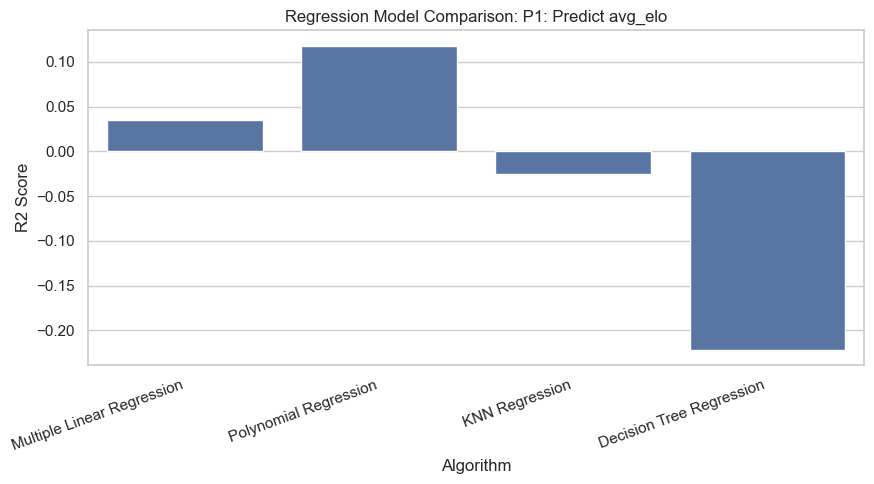

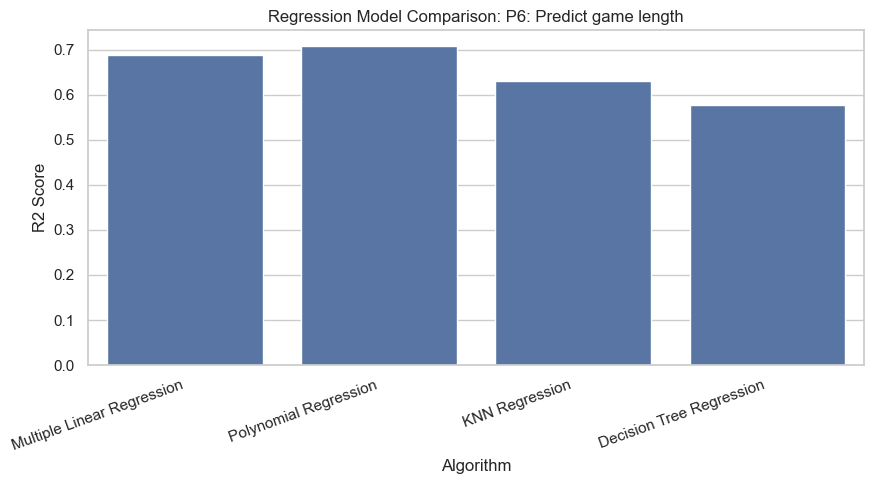

In [37]:

for pname in regression_results['Problem'].unique():

    subset = regression_results[
        regression_results['Problem'] == pname
    ]

    plt.figure(figsize=(9, 5))

    sns.barplot(
        data=subset,
        x='Algorithm',
        y='R2 Score'
    )

    plt.title(f'Regression Model Comparison: {pname}')
    plt.xticks(rotation=20, ha='right')
    plt.tight_layout()
    plt.show()



### Regression Results Interpretation

TThe regression analysis was performed for two prediction tasks: estimating a player's average Elo rating and predicting the average number of moves in their games.

For the average Elo prediction problem, the Decision Tree Regression model obtained an R² score of -0.2220. This indicates that the model did not capture the relationship between the selected player statistics and Elo rating effectively. Its predictions were less accurate than using the mean Elo value as a constant prediction. This suggests that Elo rating may depend on additional factors that are not fully represented by the selected features.

For predicting average game length, Decision Tree Regression achieved an R² score of 0.5779. This indicates that the model explained approximately 57.79% of the variation in average game length. The selected player statistics therefore provided a reasonable amount of information for estimating how long a player's games tend to last.

Overall, the results show that predicting game length was more successful with Decision Tree Regression than predicting average Elo. This suggests that playing statistics may have a clearer relationship with game duration than with a player's overall rating.


# Stage K: Classification Analysis

Classification is a supervised machine learning technique
used to predict categorical outcomes.

Two classification problems are considered:

1. High-potential player identification (P2).
2. Risky playing-style identification (P3).

The following algorithms are applied:

- Logistic Regression
- Naive Bayes
- K-Nearest Neighbors (KNN)
- Decision Tree Classifier

The models are evaluated using Accuracy, Precision,
Recall and F1-score.


In [38]:

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

classification_models = {
    'Logistic Regression': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('model', LogisticRegression(max_iter=2000))
    ]),

    'Naive Bayes': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('model', GaussianNB())
    ]),

    'KNN Classifier': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('model', KNeighborsClassifier(n_neighbors=5))
    ]),

    'Decision Tree Classifier': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('model', DecisionTreeClassifier(
            max_depth=5,
            random_state=42
        ))
    ])
}


In [39]:

classification_results = []
trained_classification_models = {}

for pname, problem in problems.items():

    if problem['kind'] != 'classification':
        continue

    X = df[problem['features']]
    y = problem['target']

    X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
        X, y,
        test_size=0.2,
        random_state=42,
        stratify=y
    )

    for model_name, model in classification_models.items():

        model.fit(X_train_c, y_train_c)

        predictions = model.predict(X_test_c)

        classification_results.append({
            'Problem': pname,
            'Algorithm': model_name,
            'Accuracy': accuracy_score(y_test_c, predictions),
            'Precision': precision_score(
                y_test_c, predictions, zero_division=0
            ),
            'Recall': recall_score(
                y_test_c, predictions, zero_division=0
            ),
            'F1 Score': f1_score(
                y_test_c, predictions, zero_division=0
            )
        })

        trained_classification_models[(pname, model_name)] = model

classification_results = pd.DataFrame(classification_results)

display(classification_results.round(4))


,Problem,Algorithm,Accuracy,Precision,Recall,F1 Score
0,P2: High-potential,Logistic Regression,0.5112,0.5089,0.5135,0.5112
1,P2: High-potential,Naive Bayes,0.4798,0.4719,0.3784,0.4200
2,P2: High-potential,KNN Classifier,0.4753,0.4732,0.4775,0.4753
3,P2: High-potential,Decision Tree Classifier,0.5426,0.5584,0.3874,0.4574
4,P3: Risky style,Logistic Regression,0.6996,0.5882,0.3947,0.4724
5,P3: Risky style,Naive Bayes,0.6951,0.5541,0.5395,0.5467
6,P3: Risky style,KNN Classifier,0.6861,0.5469,0.4605,0.5000
7,P3: Risky style,Decision Tree Classifier,0.6816,0.5352,0.5000,0.5170


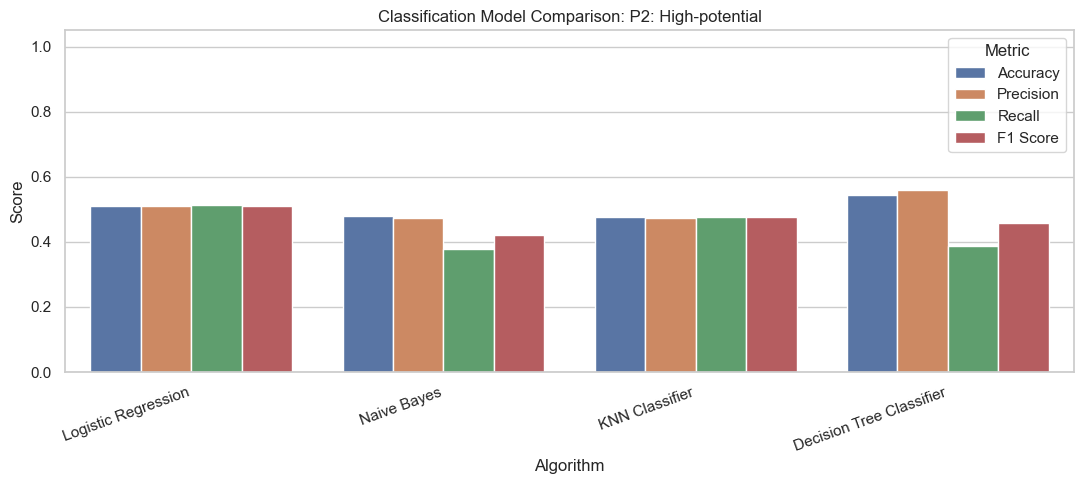

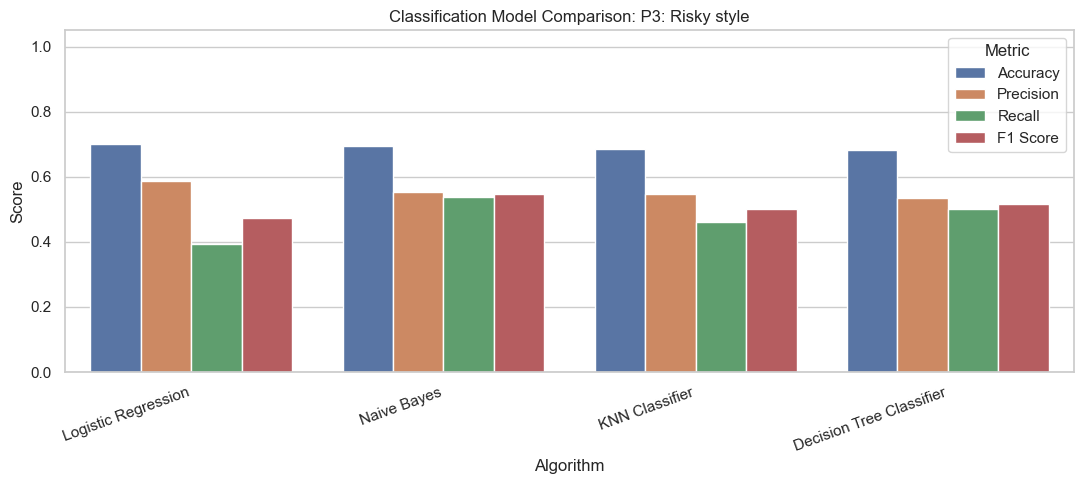

In [40]:

for pname in classification_results['Problem'].unique():

    subset = classification_results[
        classification_results['Problem'] == pname
    ]

    plot_data = subset.melt(
        id_vars='Algorithm',
        value_vars=['Accuracy', 'Precision', 'Recall', 'F1 Score'],
        var_name='Metric',
        value_name='Score'
    )

    plt.figure(figsize=(11, 5))

    sns.barplot(
        data=plot_data,
        x='Algorithm',
        y='Score',
        hue='Metric'
    )

    plt.title(f'Classification Model Comparison: {pname}')
    plt.xticks(rotation=20, ha='right')
    plt.ylim(0, 1.05)
    plt.tight_layout()
    plt.show()



### Classification Results Interpretation

The classification analysis focused on identifying high-potential players and detecting players with risky playing styles.

For the high-potential player identification task, the classification report shows that Logistic Regression achieved an accuracy of approximately 51%. Its precision and recall were also around 51% for both classes. This indicates that the model had difficulty distinguishing players whose Elo ratings were above their games-played bracket median from those below it. The selected features may not contain enough information to reliably identify high-potential players.

For the risky playing-style identification task, Logistic Regression achieved an accuracy of approximately 70%. The model performed better at identifying Class 0, with a recall of 86%, compared with a recall of 39% for Class 1. This means that it identified many non-risky players correctly but missed a considerable number of risky players.

The comparison indicates that identifying risky playing styles was more successful than identifying high-potential players. However, the relatively low recall for Class 1 shows that the risky-style classifier still needs improvement, particularly in detecting players who exhibit risky behaviour.


# Stage L: Hyperparameter Tuning

Hyperparameter tuning is used to find suitable configurations for machine learning algorithms.

GridSearchCV tests different combinations of hyperparameters using five-fold cross-validation.

In this project, tuning is performed using:

1. Logistic Regression
2. KNN Classifier
3. Decision Tree Classifier

The best configurations are selected using the F1-score as the evaluation metric.


In [41]:

from sklearn.model_selection import GridSearchCV
from sklearn.base import clone

param_grids = {
    'Logistic Regression': {
        'model__C': [0.01, 0.1, 1, 10]
    },

    'KNN Classifier': {
        'model__n_neighbors': [3, 5, 7, 9, 11],
        'model__weights': ['uniform', 'distance']
    },

    'Decision Tree Classifier': {
        'model__max_depth': [3, 5, 7, 10, None],
        'model__min_samples_split': [2, 5, 10]
    }
}

tuning_results = []
best_classification_models = {}

for pname, problem in problems.items():

    if problem['kind'] != 'classification':
        continue

    X = df[problem['features']]
    y = problem['target']

    X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
        X, y,
        test_size=0.2,
        random_state=42,
        stratify=y
    )

    for model_name in param_grids:

        base_model = clone(classification_models[model_name])

        grid = GridSearchCV(
            estimator=base_model,
            param_grid=param_grids[model_name],
            scoring='f1',
            cv=5,
            n_jobs=-1
        )

        grid.fit(X_train_c, y_train_c)

        best_model = grid.best_estimator_
        predictions = best_model.predict(X_test_c)

        best_classification_models[(pname, model_name)] = best_model

        tuning_results.append({
            'Problem': pname,
            'Algorithm': model_name,
            'Best Parameters': grid.best_params_,
            'Best CV F1': grid.best_score_,
            'Test Accuracy': accuracy_score(y_test_c, predictions),
            'Test Precision': precision_score(
                y_test_c, predictions, zero_division=0
            ),
            'Test Recall': recall_score(
                y_test_c, predictions, zero_division=0
            ),
            'Test F1': f1_score(
                y_test_c, predictions, zero_division=0
            )
        })

tuning_results = pd.DataFrame(tuning_results)

display(tuning_results.round(4))


,Problem,Algorithm,Best Parameters,Best CV F1,Test Accuracy,Test Precision,Test Recall,Test F1
0,P2: High-potential,Logistic Regression,{'model__C': 1},0.5371,0.5112,0.5089,0.5135,0.5112
1,P2: High-potential,KNN Classifier,"{'model__n_neighbors': 7, 'model__weights': 'd...",0.5011,0.4753,0.4700,0.4234,0.4455
2,P2: High-potential,Decision Tree Classifier,"{'model__max_depth': None, 'model__min_samples...",0.5218,0.5426,0.5429,0.5135,0.5278
3,P3: Risky style,Logistic Regression,{'model__C': 1},0.4994,0.6996,0.5882,0.3947,0.4724
4,P3: Risky style,KNN Classifier,"{'model__n_neighbors': 3, 'model__weights': 'u...",0.4485,0.6278,0.4533,0.4474,0.4503
5,P3: Risky style,Decision Tree Classifier,"{'model__max_depth': None, 'model__min_samples...",0.4816,0.6592,0.5000,0.5526,0.5250


In [42]:

before_after = classification_results.merge(
    tuning_results[
        ['Problem', 'Algorithm', 'Test Accuracy', 'Test F1']
    ],
    on=['Problem', 'Algorithm']
)

before_after = before_after.rename(columns={
    'Accuracy': 'Before Tuning Accuracy',
    'F1 Score': 'Before Tuning F1',
    'Test Accuracy': 'After Tuning Accuracy',
    'Test F1': 'After Tuning F1'
})

display(before_after.round(4))


,Problem,Algorithm,Before Tuning Accuracy,Precision,Recall,Before Tuning F1,After Tuning Accuracy,After Tuning F1
0,P2: High-potential,Logistic Regression,0.5112,0.5089,0.5135,0.5112,0.5112,0.5112
1,P2: High-potential,KNN Classifier,0.4753,0.4732,0.4775,0.4753,0.4753,0.4455
2,P2: High-potential,Decision Tree Classifier,0.5426,0.5584,0.3874,0.4574,0.5426,0.5278
3,P3: Risky style,Logistic Regression,0.6996,0.5882,0.3947,0.4724,0.6996,0.4724
4,P3: Risky style,KNN Classifier,0.6861,0.5469,0.4605,0.5000,0.6278,0.4503
5,P3: Risky style,Decision Tree Classifier,0.6816,0.5352,0.5000,0.5170,0.6592,0.5250


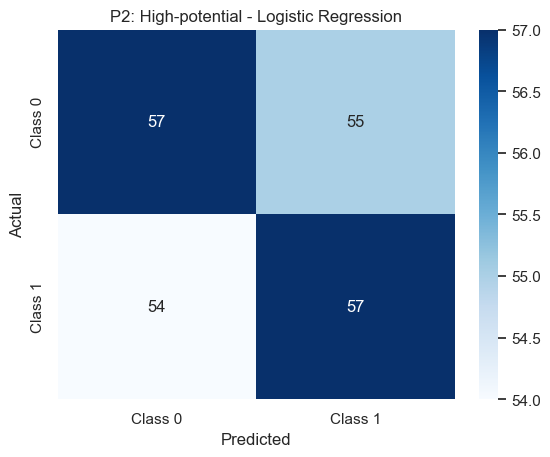

Best algorithm: Logistic Regression
              precision    recall  f1-score   support

           0       0.51      0.51      0.51       112
           1       0.51      0.51      0.51       111

    accuracy                           0.51       223
   macro avg       0.51      0.51      0.51       223
weighted avg       0.51      0.51      0.51       223



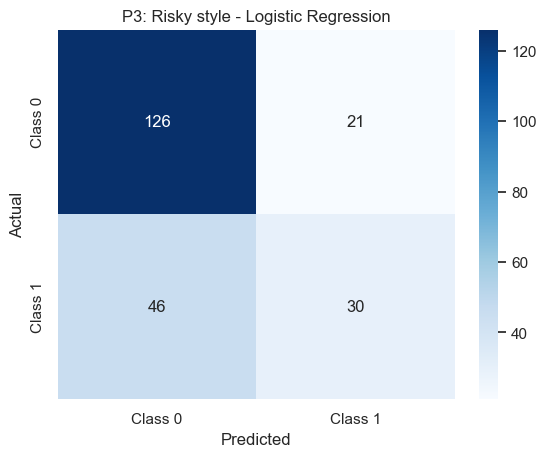

Best algorithm: Logistic Regression
              precision    recall  f1-score   support

           0       0.73      0.86      0.79       147
           1       0.59      0.39      0.47        76

    accuracy                           0.70       223
   macro avg       0.66      0.63      0.63       223
weighted avg       0.68      0.70      0.68       223



In [43]:

for pname, problem in problems.items():

    if problem['kind'] != 'classification':
        continue

    X = df[problem['features']]
    y = problem['target']

    X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
        X, y,
        test_size=0.2,
        random_state=42,
        stratify=y
    )

    # Select using cross-validation F1, not test-set performance
    subset = tuning_results[
        tuning_results['Problem'] == pname
    ]

    best_name = subset.loc[
        subset['Best CV F1'].idxmax(), 'Algorithm'
    ]

    best_model = best_classification_models[(pname, best_name)]
    predictions = best_model.predict(X_test_c)

    cm = confusion_matrix(y_test_c, predictions)

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=['Class 0', 'Class 1'],
        yticklabels=['Class 0', 'Class 1']
    )

    plt.title(f'{pname} - {best_name}')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()

    print("Best algorithm:", best_name)
    print(classification_report(
        y_test_c,
        predictions,
        zero_division=0
    ))



### Hyperparameter Tuning Interpretation

GridSearchCV was applied to Logistic Regression, KNN and Decision Tree Classifier using five-fold cross-validation. The parameter combinations were evaluated using F1-score to select configurations that balance precision and recall.

The tuning results were evaluated separately for high-potential player identification and risky playing-style identification. The confusion matrices and classification reports show that Logistic Regression was selected as the best-performing algorithm for both tasks based on cross-validation F1-score.

For high-potential player identification, the selected Logistic Regression model achieved approximately 51% accuracy, with an F1-score of approximately 0.51. This indicates that tuning did not overcome the difficulty of separating the two player groups using the available features.

For risky playing-style identification, the selected model achieved approximately 70% accuracy. However, its recall for Class 1 remained 39%, showing that many risky players were still incorrectly classified as non-risky.

These results indicate that hyperparameter tuning helps select suitable model configurations, but it does not necessarily guarantee high predictive performance. The quality and predictive power of the selected features also play an important role.


## References

1. Lichess Elite Database, October 2025.
   https://database.nikonoel.fr/

2. Scikit-learn Documentation – Linear Regression.
   https://scikit-learn.org/stable/modules/linear_model.html

3. Scikit-learn Documentation – Classification.
   https://scikit-learn.org/stable/supervised_learning.html

4. Scikit-learn Documentation – GridSearchCV.
   https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html

5. Scikit-learn Documentation – KMeans Clustering.
   https://scikit-learn.org/stable/modules/clustering.html

6. Pandas Documentation.
   https://pandas.pydata.org/docs/

7. Matplotlib Documentation.
   https://matplotlib.org/stable/contents.html
